In [1]:
import glob
import os
import numpy as np
import xarray as xr
from netCDF4 import Dataset
import matplotlib.pyplot as plt

In [2]:
# files = sorted(glob.glob("/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_????.nc"))
# output_file = "/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_1950_2025.nc"

# print(f"Found {len(files)} files")
# print("First:", files[0])
# print("Last: ", files[-1])

# def copy_attributes(source, destination):
#     """Copy variable attributes except _FillValue."""
#     for attribute in source.ncattrs():
#         if attribute != "_FillValue":
#             destination.setncattr(attribute, source.getncattr(attribute))

# with Dataset(files[0], "r") as first:
#     reference_latitude = first.variables["latitude"][:]
#     reference_longitude = first.variables["longitude"][:]

#     with Dataset(output_file, "w", format="NETCDF4") as output:
#         # Dimensions
#         output.createDimension("valid_time", None)
#         output.createDimension("latitude", len(reference_latitude))
#         output.createDimension("longitude", len(reference_longitude))

#         # Global attributes
#         for attribute in first.ncattrs():
#             output.setncattr(attribute, first.getncattr(attribute))

#         output.setncattr(
#             "combination_note",
#             "Monthly ERA5-Land SWE files combined sequentially for 1950-2025"
#         )

#         # Coordinate variables
#         output_time = output.createVariable(
#             "valid_time",
#             first.variables["valid_time"].datatype,
#             ("valid_time",)
#         )
#         copy_attributes(first.variables["valid_time"], output_time)

#         output_latitude = output.createVariable(
#             "latitude", "f8", ("latitude",)
#         )
#         copy_attributes(first.variables["latitude"], output_latitude)
#         output_latitude[:] = reference_latitude

#         output_longitude = output.createVariable(
#             "longitude", "f8", ("longitude",)
#         )
#         copy_attributes(first.variables["longitude"], output_longitude)
#         output_longitude[:] = reference_longitude

#         # Scalar coordinate
#         output_number = output.createVariable("number", "i8")
#         copy_attributes(first.variables["number"], output_number)
#         output_number.assignValue(first.variables["number"].getValue())

#         # Experiment-version coordinate
#         output_expver = output.createVariable(
#             "expver", str, ("valid_time",)
#         )
#         copy_attributes(first.variables["expver"], output_expver)

#         # SWE variable
#         source_sd = first.variables["sd"]
#         fill_value = getattr(source_sd, "_FillValue", None)

#         sd_options = {
#             "zlib": True,
#             "complevel": 4,
#             "shuffle": True,
#             "chunksizes": (1, 100, 400)
#         }

#         if fill_value is not None:
#             sd_options["fill_value"] = fill_value

#         output_sd = output.createVariable(
#             "sd",
#             "f4",
#             ("valid_time", "latitude", "longitude"),
#             **sd_options
#         )
#         copy_attributes(source_sd, output_sd)

#         position = 0

#         for file_number, filename in enumerate(files, start=1):
#             print(f"[{file_number:02d}/{len(files)}] Processing {filename}")

#             with Dataset(filename, "r") as source:
#                 # Check that every file uses the same spatial grid
#                 if not np.array_equal(
#                     source.variables["latitude"][:],
#                     reference_latitude
#                 ):
#                     raise ValueError(f"Latitude mismatch in {filename}")

#                 if not np.array_equal(
#                     source.variables["longitude"][:],
#                     reference_longitude
#                 ):
#                     raise ValueError(f"Longitude mismatch in {filename}")

#                 number_of_months = len(source.dimensions["valid_time"])

#                 output_time[position:position + number_of_months] = (
#                     source.variables["valid_time"][:]
#                 )

#                 output_expver[position:position + number_of_months] = (
#                     source.variables["expver"][:]
#                 )

#                 # Write one month at a time
#                 for month in range(number_of_months):
#                     output_sd[position + month, :, :] = (
#                         source.variables["sd"][month, :, :]
#                     )

#                 position += number_of_months

#         print(f"Monthly records written: {position}")

#         if position != 912:
#             raise ValueError(f"Expected 912 months, wrote {position}")

# print("Finished")
# print("Output:", os.path.abspath(output_file))
# print("Size:", round(os.path.getsize(output_file) / 1e9, 2), "GB")

In [3]:
file = "/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_1950_2025.nc"

ds = xr.open_dataset(file)

print("SWE units:", ds["sd"].attrs.get("units"))

ds

SWE units: m of water equivalent


<xarray.Dataset> Size: 12GB
Dimensions:     (valid_time: 912, latitude: 901, longitude: 3600)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-12-01
  * latitude    (latitude) float64 7kB 90.0 89.9 89.8 89.7 ... 0.3 0.2 0.1 0.0
  * longitude   (longitude) float64 29kB -180.0 -179.9 -179.8 ... 179.8 179.9
    number      int64 8B ...
    expver      (valid_time) <U4 15kB ...
Data variables:
    sd          (valid_time, latitude, longitude) float32 12GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-10T03:50 GRIB to CDM+CF via cfgrib-0.9.1...
    combination_note:        Monthly ERA5-Land SWE files combined sequentiall...

In [4]:
ds["swe"] = ds["sd"] * 1000

ds["swe"].attrs = ds["sd"].attrs.copy()
ds["swe"].attrs["units"] = "mm"
ds["swe"].attrs["long_name"] = "Snow water equivalent"

ds

<xarray.Dataset> Size: 24GB
Dimensions:     (valid_time: 912, latitude: 901, longitude: 3600)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-12-01
  * latitude    (latitude) float64 7kB 90.0 89.9 89.8 89.7 ... 0.3 0.2 0.1 0.0
  * longitude   (longitude) float64 29kB -180.0 -179.9 -179.8 ... 179.8 179.9
    number      int64 8B ...
    expver      (valid_time) <U4 15kB ...
Data variables:
    sd          (valid_time, latitude, longitude) float32 12GB nan nan ... nan
    swe         (valid_time, latitude, longitude) float32 12GB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-10T03:50 GRIB to CDM+CF via cfgrib-0.9.1...
    combination_note:        Monthly ERA5-Land SWE files combined sequentiall...

In [5]:
ds_out = ds[["swe"]]

output_file = "/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_mm_1950_2025.nc"

encoding = {
    "swe": {
        "dtype": "float32",
        "zlib": True,
        "complevel": 4,
        "chunksizes": (1, 100, 400)
    }
}

ds_out.to_netcdf(
    output_file,
    engine="netcdf4",
    encoding=encoding
)

ds.close()

print("Saved:", output_file)

Saved: /home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_mm_1950_2025.nc


In [6]:
ds = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_mm_1950_2025.nc", chunks="auto")

swe = ds["swe"]

swe = swe.rename({
    'valid_time': 'time',
    'latitude': 'lat',
    'longitude': 'lon'
})

swe = swe.sortby('lat')
swe = swe.assign_coords(
    lon = (((swe.lon + 180) % 360) - 180)
).sortby('lon')
swe = swe.sel(time=slice("1950-01-01", "2024-12-31"))
swe

<xarray.DataArray 'swe' (time: 900, lat: 901, lon: 3600)> Size: 12GB
dask.array<getitem, shape=(900, 901, 3600), dtype=float32, chunksize=(10, 901, 3600), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float64 7kB 0.0 0.1 0.2 0.3 0.4 ... 89.6 89.7 89.8 89.9 90.0
  * lon      (lon) float64 29kB -180.0 -179.9 -179.8 ... 179.7 179.8 179.9
    number   int64 8B ...
    expver   (time) <U4 14kB dask.array<chunksize=(900,), meta=np.ndarray>
Attributes: (12/31)
    GRIB_paramId:                             141
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3243600
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m of water equivalent
    long_name:                                Snow water equivalent
    units:                                    mm
    standard_name:                            lwe_thickness_of_surface_snow_a...
    GRIB_surface:                             0.0

In [7]:
lat = swe.lat
lon = swe.lon
print(abs(lat[1] - lat[0]).values)
print(abs(lon[1] - lon[0]).values)

0.10000000000083592
0.09999999999999432


In [8]:
swe.min().compute()

<xarray.DataArray 'swe' ()> Size: 4B
array(-7.345365e-22, dtype=float32)
Coordinates:
    number   int64 8B 0

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/dask/array/reductions.py:325: RuntimeWarning: All-NaN slice encountered
  return np.nanmax(x_chunk, axis=axis, keepdims=keepdims)


In [9]:
swe.max().compute()

<xarray.DataArray 'swe' ()> Size: 4B
array(10000., dtype=float32)
Coordinates:
    number   int64 8B 0

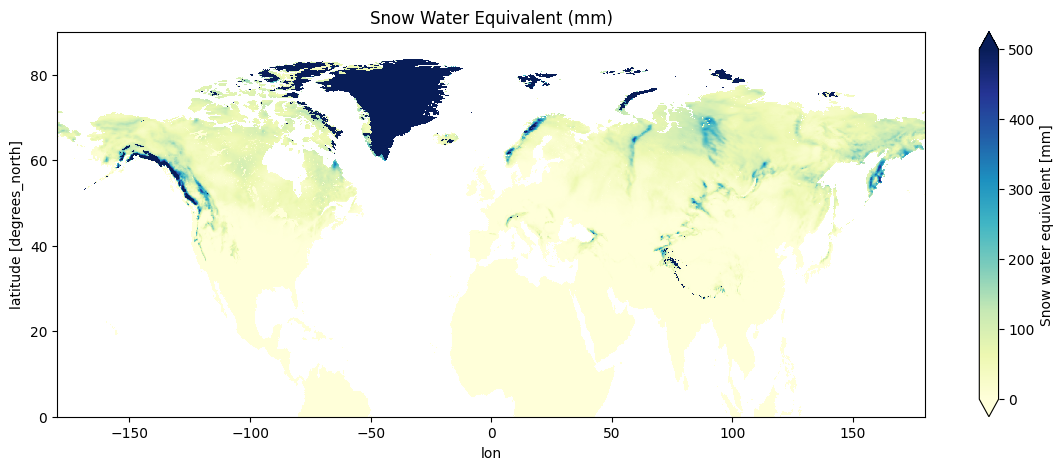

In [12]:
swe.isel(time=-1).plot(
    cmap="YlGnBu",
    figsize=(14,5),
    vmin=0,
    vmax=500) 

plt.title("Snow Water Equivalent (mm)")
plt.show()

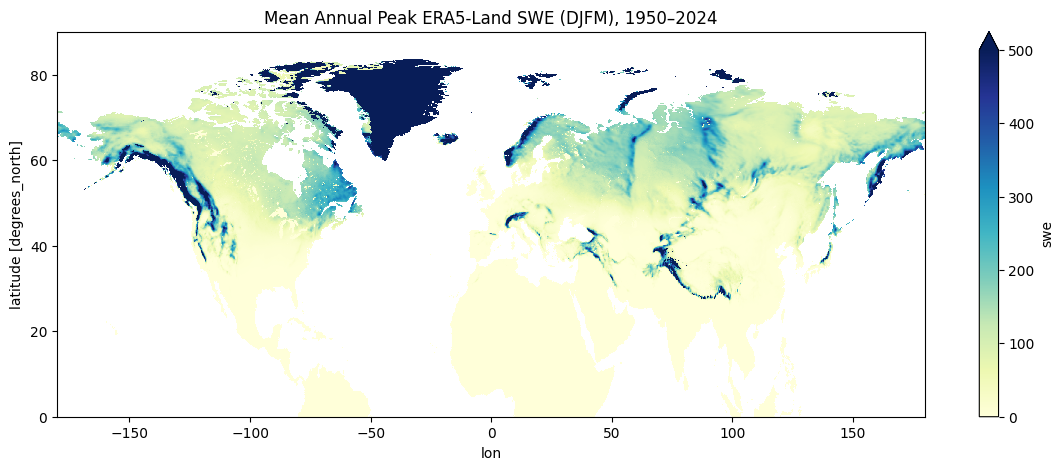

In [14]:
# Select December–March
winter = swe.where(swe.time.dt.month.isin([12, 1, 2, 3]), drop=True)

# Assign December to the following snow year
snow_year = xr.where(
    winter.time.dt.month == 12,
    winter.time.dt.year + 1,
    winter.time.dt.year
)

winter = winter.assign_coords(snow_year=("time", snow_year.data))

# Maximum monthly SWE during each DJFM season
peak_swe = winter.groupby("snow_year").max("time")

# Retain complete winters only: Dec 1950–Mar 1951 through Dec 2023–Mar 2024
peak_swe = peak_swe.sel(snow_year=slice(1950, 2024))

# Climatological mean peak SWE
climatological_peak_swe = peak_swe.mean("snow_year")

climatological_peak_swe.clip(min=0).plot(
    cmap="YlGnBu",
    figsize=(14, 5),
    vmin=0,
    vmax=500,
    extend="max"
)

plt.title("Mean Annual Peak ERA5-Land SWE (DJFM), 1950–2024")
plt.show()

In [15]:
# Remove unnecessary ERA5 metadata coordinates
swe_out = swe.reset_coords(["number", "expver"], drop=True)

output_file = (
    "/home/mgurazada/snowdroughts_thirst/data/era5_land_swe/"
    "era5_land_swe_mm_1950_2024_processed.nc"
)

encoding = {
    "swe": {
        "dtype": "float32",
        "zlib": True,
        "complevel": 4,
        "shuffle": True,
        "chunksizes": (12, 100, 400)
    }
}

swe_out.to_dataset(name="swe").to_netcdf(
    output_file,
    engine="netcdf4",
    encoding=encoding
)

print("Saved:", output_file)

Saved: /home/mgurazada/snowdroughts_thirst/data/era5_land_swe/era5_land_swe_mm_1950_2024_processed.nc
